# 07 - Model Evaluation

Evaluate the logistic regression from `06_modelling` on the held-out test set (first and only use of the test set for performance).

1. Predict the probability of default (PD) on train and test.
2. **AUC, Gini, KS** on both sets: test performance is the headline; a small train-test gap means no overfitting.
3. **ROC curve** and **KS curve**.
4. **Gains table** (deciles): bad rate per risk band and share of bads captured.

## 1. Setup

In [1]:
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import pandas as pd
from sklearn.metrics import roc_curve

# Add project root to sys.path so `src` can be imported from the notebooks/ folder
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.evaluation import gains_table, performance_summary
from src.model import predict_pd

DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

# Chart colors: categorical slots 1-2, muted ink for reference lines / text
BLUE, ORANGE = "#2a78d6", "#eb6834"
MUTED, GRID = "#8a8985", "#e6e5e1"
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": MUTED,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "lines.linewidth": 2,
})

## 2. Load model and data

In [2]:
with open(OUTPUT_DIR / "logit_model.pkl", "rb") as f:
    model = pickle.load(f)
features = pd.read_csv(OUTPUT_DIR / "model_features.csv")["feature"].tolist()

woe_train = pd.read_pickle(DATA_DIR / "woe_train.pkl")
woe_test = pd.read_pickle(DATA_DIR / "woe_test.pkl")
y_train, y_test = woe_train["TARGET"], woe_test["TARGET"]

pd_train = predict_pd(model, woe_train[features])
pd_test = predict_pd(model, woe_test[features])
print(f"{len(features)} features | train {len(pd_train):,} | test {len(pd_test):,}")
print(f"Mean PD vs default rate - train: {pd_train.mean():.2%} / {y_train.mean():.2%}, "
      f"test: {pd_test.mean():.2%} / {y_test.mean():.2%}")

16 features | train 246,008 | test 61,503
Mean PD vs default rate - train: 8.07% / 8.07%, test: 8.04% / 8.07%


## 3. AUC, Gini, KS

Rough guide for retail scorecards: Gini > 0.4 and KS > 0.3 are acceptable; a train-test Gini gap above ~0.03 hints at overfitting.

In [3]:
metrics = pd.DataFrame({
    "train": performance_summary(y_train, pd_train),
    "test": performance_summary(y_test, pd_test),
})
metrics["gap"] = metrics["train"] - metrics["test"]
metrics.round(4)

,train,test,gap
auc,0.7374,0.7386,-0.0012
gini,0.4748,0.4772,-0.0024
ks,0.3535,0.3572,-0.0037


## 4. ROC curve

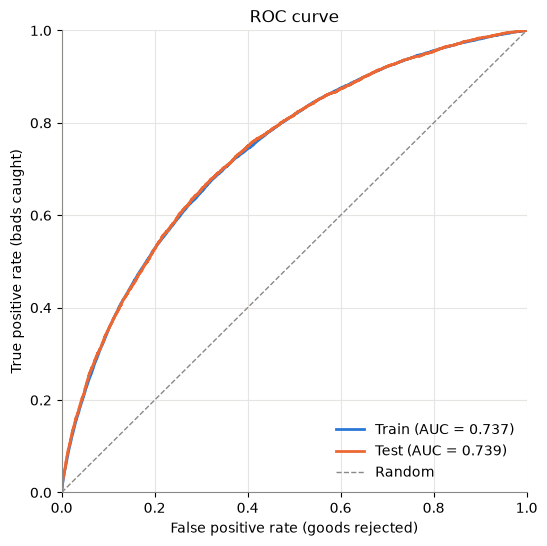

In [4]:
fig, ax = plt.subplots(figsize=(6, 6))
for name, y, p, color in [("Train", y_train, pd_train, BLUE), ("Test", y_test, pd_test, ORANGE)]:
    fpr, tpr, _ = roc_curve(y, p)
    ax.plot(fpr, tpr, color=color, label=f"{name} (AUC = {metrics.loc['auc', name.lower()]:.3f})")
ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1, label="Random")
ax.set(xlabel="False positive rate (goods rejected)", ylabel="True positive rate (bads caught)",
       title="ROC curve", xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="lower right", frameon=False)
fig.savefig(OUTPUT_DIR / "roc_curve.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. KS curve (test)

Cumulative share of bads and goods as the cut-off moves from the riskiest applicants down. KS is the largest vertical gap.

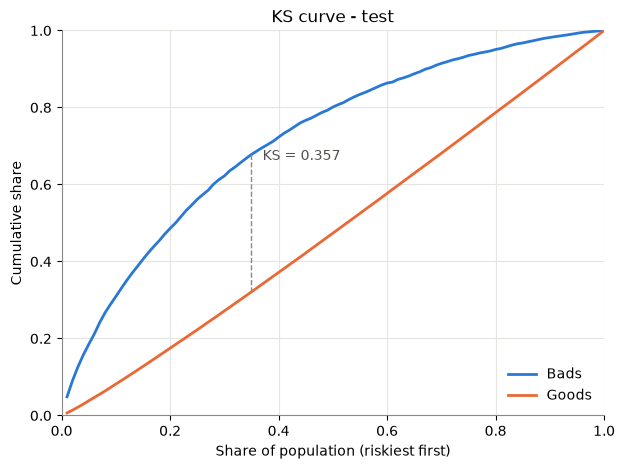

In [5]:
fine = gains_table(y_test, pd_test, n_bins=100)
ks_band = fine["ks"].idxmax()
x = fine["cum_pop_pct"]

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(x, fine["cum_bad_pct"], color=BLUE, label="Bads")
ax.plot(x, fine["cum_good_pct"], color=ORANGE, label="Goods")
ax.vlines(x[ks_band], fine.loc[ks_band, "cum_good_pct"], fine.loc[ks_band, "cum_bad_pct"],
          color=MUTED, linestyle="--", linewidth=1)
ax.annotate(f"KS = {metrics.loc['ks', 'test']:.3f}", (x[ks_band], fine.loc[ks_band, "cum_bad_pct"]),
            xytext=(8, -4), textcoords="offset points", color="#52514e")
ax.set(xlabel="Share of population (riskiest first)", ylabel="Cumulative share",
       title="KS curve - test", xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="lower right", frameon=False)
fig.savefig(OUTPUT_DIR / "ks_curve.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Gains table (test, deciles)

Band 1 = riskiest 10%. A good model has bad rates falling steadily from band 1 to band 10 and captures most bads in the first few bands.

In [6]:
gains = gains_table(y_test, pd_test, n_bins=10)
gains.style.format({
    "bad_rate": "{:.2%}", "min_score": "{:.4f}", "max_score": "{:.4f}",
    "cum_pop_pct": "{:.0%}", "cum_bad_pct": "{:.1%}", "cum_good_pct": "{:.1%}", "ks": "{:.3f}",
})

,n,n_bad,bad_rate,min_score,max_score,cum_pop_pct,cum_bad_pct,cum_good_pct,ks
band,,,,,,,,,
1,6151,1535,24.96%,0.1721,0.6060,10%,30.9%,8.2%,0.228
2,6150,878,14.28%,0.1214,0.1721,20%,48.6%,17.5%,0.311
3,6150,676,10.99%,0.0927,0.1214,30%,62.2%,27.2%,0.350
4,6150,501,8.15%,0.0728,0.0927,40%,72.3%,37.2%,0.351
5,6151,388,6.31%,0.0580,0.0728,50%,80.1%,47.4%,0.328
6,6150,309,5.02%,0.0464,0.0580,60%,86.3%,57.7%,0.287
7,6150,254,4.13%,0.0364,0.0464,70%,91.5%,68.1%,0.233
8,6150,179,2.91%,0.0277,0.0364,80%,95.1%,78.7%,0.164
9,6150,155,2.52%,0.0190,0.0277,90%,98.2%,89.3%,0.089


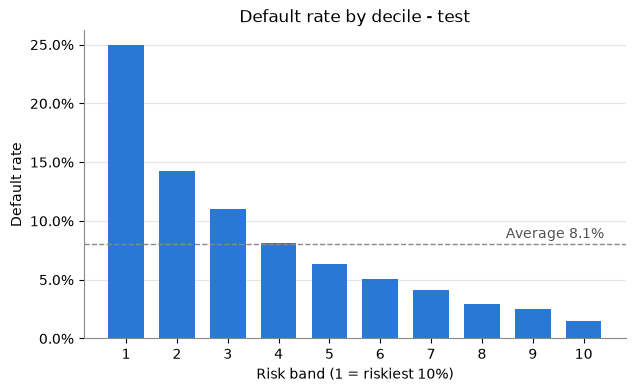

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(gains.index, gains["bad_rate"], color=BLUE, width=0.7)
ax.axhline(y_test.mean(), color=MUTED, linestyle="--", linewidth=1)
ax.annotate(f"Average {y_test.mean():.1%}", (10.4, y_test.mean()), xytext=(0, 4),
            textcoords="offset points", ha="right", color="#52514e")
ax.set(xlabel="Risk band (1 = riskiest 10%)", ylabel="Default rate", title="Default rate by decile - test",
       xticks=gains.index)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(axis="x", visible=False)
fig.savefig(OUTPUT_DIR / "decile_bad_rate.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Save artifacts

In [8]:
metrics.to_csv(OUTPUT_DIR / "metrics.csv")
gains.to_csv(OUTPUT_DIR / "gains_table_test.csv")
print("Saved metrics.csv, gains_table_test.csv, roc_curve.png, ks_curve.png, decile_bad_rate.png")

Saved metrics.csv, gains_table_test.csv, roc_curve.png, ks_curve.png, decile_bad_rate.png
